[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/4_subspace_alignment.ipynb)

# Subspace alignment across encoders and areas

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the subspace alignment of the top-k eigenvectors of G(x) and J(x), for models fitted to the same area (solid) or the same model fitted to different areas (dashed), averaged over images (paper Fig. 4D-E).

* **Requirements**: the datasets and checkpoints (see the README) and GPUs; Modal is optional.

* **Time**: about 100 min with the settings below (two configurations, 200 images, one GPU); `N_IMAGES = 3` takes about 2 min.

<details><summary>Details</summary>

* **Steps**: (1) estimate G(x) and J(x) for the test images of every (encoder, area) configuration, (2) alignment between configurations, (3) plot. The G(x) estimation is the expensive step; the images are independent, so they are split over workers (GPUs) without changing any result. No DDP/FSDP is needed: nothing is communicated between GPUs.
* The supporting functions are in `multigeom.pipeline.distribute` and `multigeom.pipeline.alignment`; the plot is `figures/alignment.py`. This notebook only sets parameters and calls them.

</details>

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 2.38 μs


### 1.2. Imports, parameters and example scenarios

Set `CONFIGS`, `N_IMAGES`, `BACKEND`, `DEVICE` and `NUM_WORKERS` in the next cell (plus `GPU_TYPE` and `MAX_COST_USD` for Modal). Typical values:

| Scenario | `CONFIGS` | `N_IMAGES` | `BACKEND` | `DEVICE` | `NUM_WORKERS` |
|---|---|---|---|---|---|
| quick check on this machine | `("inception", "V1")` | 3 | `"local"` | `"gpu"` | 1 |
| one configuration, all images, this machine | `("inception", "V1")` | 200 | `"local"` | `"gpu"` | 1 |
| two configurations, all images, this machine (to plot Fig. 4D-E) | `[("inception", "V1"), ("inception", "V4")]` | 200 | `"local"` | `"gpu"` | 1 |
| one configuration, all images, Modal | `("inception", "V1")` | 200 | `"modal"` | `"gpu"` | 10 |
| all configurations, all images, Modal | `sa.ALL_CONFIGS` (inception and resnet50 x V1 and V4) | 200 | `"modal"` | `"gpu"` | 10 |

<details><summary>Details</summary>

* `CONFIGS` is one `(encoder, area)` pair or a list of them. `NUM_WORKERS` workers run in parallel, one GPU (or one CPU process) each; on this machine it is capped at the number of GPUs present, and a Modal Starter plan allows 10 at once.
* The alignment compares two configurations, so with a single one this notebook estimates G(x) and J(x) but cannot plot Fig. 4D-E: add a second one (for example `[("inception", "V1"), ("inception", "V4")]`) to get the dashed V1-vs-V4 curve.
* `DEVICE = "cpu"` works but is slow (about 15 min per image on a 32-core CPU, using all cores), so there is no CPU scenario here.
* On Modal you pay for GPU time. The estimate printed below uses third-party prices and is a guide, not a bill; the launch is refused if it exceeds `MAX_COST_USD`.

</details>

time: <1 sec

In [2]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root (the folder containing environment.yml): data/ and runs/
# are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

sys.path.insert(0, str(root))  # the figures/ folder of this repository

# import custom package
from multigeom.utils import show_figure
from figures.alignment import plot_alignment
from multigeom.pipeline import alignment, distribute as sa

importlib.reload(sa)  # update the module without restarting the kernel

# parameters (see the table above for examples)
# (encoder, area), or a list of them; sa.ALL_CONFIGS = all four
CONFIGS = [("inception", "V1"), ("inception", "V4")]

N_IMAGES = 200  # first N test images (the paper uses 200)
BACKEND = "local"  # "local" (this machine) | "modal" (serverless GPUs)
DEVICE = "gpu"  # "gpu" | "cpu" (Modal: "gpu")

# parallel workers (local GPU: at most the GPUs present; Modal Starter plan: 10)
NUM_WORKERS = 1
GPU_TYPE = "A100"  # Modal only
MAX_COST_USD = 2.0  # Modal only: the launch is refused above this estimate

# the scenario to run
scenario = sa.Scenario(
    configs=CONFIGS,
    n_images=N_IMAGES,
    backend=BACKEND,
    device=DEVICE,
    num_workers=NUM_WORKERS,
    gpu_type=GPU_TYPE,
    max_cost_usd=MAX_COST_USD,
)

RUN = True  # False: only print the estimate. True: launch the computation.

# True: first delete the per-image results of this scenario, to recompute from scratch
# (False: resume where an earlier run stopped)
RESTART = False

print(scenario)
sa.print_estimate(scenario)  # what this would take (and cost, on Modal)

Scenario(configs=(('inception', 'V1'), ('inception', 'V4')), n_images=200, backend='local', device='gpu', num_workers=1, gpu_type='A100', seconds_per_image=None, startup_s=15.0, max_cost_usd=2.0)
400 image computations on local, 1 GPU worker(s): ~100.2 GPU-min in total, ~100.2 min wall-clock
CPU times: user 3.01 s, sys: 81.1 ms, total: 3.09 s
Wall time: 629 ms


CostEstimate(n_computations=400, n_workers=1, gpu_seconds=6015.0, wall_seconds=6015.0, cost_usd=None)

### 1.3. Download checkpoints and data

The trained encoders and diffusion models come from Hugging Face; TinyImageNet gives the test images (240 MB the first time).

time: <1 sec

In [3]:
%%time

from huggingface_hub import snapshot_download

from multigeom.datasets import download_tinyimagenet

# the trained encoders and diffusion models (files that are already there are kept; the
# archive/ folder of older checkpoints is skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns="archive/*",
)

# TinyImageNet, for the test images (240 MB the first time, nothing afterwards)
download_tinyimagenet()

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 535 ms, sys: 85.1 ms, total: 620 ms
Wall time: 968 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 2. Estimate G(x) and J(x) for every image and configuration

The `local` backend runs one detached process per GPU and resumes where it stopped; the `modal` backend runs on Modal GPUs and downloads the results to `runs/per_image/`.

time: <1 sec

<details><summary>Details</summary>

* **local**: the processes keep running if the notebook kernel dies, and relaunching skips the finished images. Logs are in `runs/logs/`. Several processes on one GPU are slower than one, so `num_gpus` is capped at the number of GPUs present.
* **modal**: needs `pip install modal` and `modal token new` once. The checkpoints and test images are uploaded to a Modal volume the first time, one container with one GPU runs each worker's shards, and the progress bar counts the finished images on the volume (it can lag by about 30 s). Interrupting the kernel cancels the Modal calls. Not exercised by the automated tests (they need your Modal account).
* **Restart from scratch**: set `RESTART = True` (above) before launching. This deletes only the per-image files of this scenario's configurations and first `n_images` images (locally, and on the Modal volume), never checkpoints. To stop running workers, interrupt the wait cell or call `sa.stop_workers()`.

</details>

In [4]:
%%time
if not RUN:
    print("RUN is False: nothing was started. Set RUN = True above to launch.")
else:
    # 1. refuse a Modal launch above the budget, and resolve the number of workers
    sa.check_budget(scenario, run=True)
    device, num_workers = sa.resolve_workers(scenario)

    # the estimation skips images that exist: a restart from scratch deletes them first
    if RESTART:
        sa.clear_results(scenario.configs, scenario.n_images)
        if scenario.backend == "modal":
            sa.modal_clear(scenario.configs, scenario.n_images)

    # 2. split the images into one shard per worker (finished images are left out)
    # images already done are left out
    workers = sa.make_shards(
        scenario.configs, scenario.n_images, num_workers, runs_dir="runs"
    )
    print(
        f"{len(workers)} worker(s):",
        [[(s.encoder, s.area, s.start, s.end) for s in w] for w in workers],
    )

    # 3. launch the workers, locally or on Modal
    if not workers:
        procs = []
        print("All images are already computed: nothing to launch.")
    elif scenario.backend == "local":
        procs = sa.launch_local(workers, use_gpu=device == "gpu")
        for p in procs:
            print(p)
    else:
        sa.modal_upload(scenario.configs)
        sa.launch_modal(workers, gpu_type=scenario.gpu_type)
        sa.modal_download(scenario.configs, scenario.n_images)

400 image computations on local, 1 GPU worker(s): ~100.2 GPU-min in total, ~100.2 min wall-clock
1 worker(s): [[('inception', 'V1', 0, 200), ('inception', 'V4', 0, 200)]]
{'worker': 0, 'pid': 224208, 'device': 'cuda:0', 'log': '/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs/logs/worker0.log'}
CPU times: user 9.93 ms, sys: 12 ms, total: 21.9 ms
Wall time: 25.7 ms


### 2.1. Wait for the local workers (local backend)

This cell waits for the background workers and shows a progress bar (about 15 s per image on a recent GPU). **Interrupting the kernel stops the workers**; finished images are kept and launching again resumes.

time: 95 min (2 configs, 1 GPU), 1 min (quick config, 1 GPU)

<details><summary>Details</summary>

The progress bar shows images done out of the total, the elapsed time and an estimate of the time left, and refreshes every 15 s; an image takes 15 s to 15 min (CPU). To only stop waiting and leave the workers running, pass `stop_on_interrupt=False`. If the kernel dies the workers keep running; `sa.stop_workers()` stops them from a later session. The Modal backend already waits inside the launch cell.

</details>

In [5]:
%%time
if scenario.backend == "local":
    # procs: the workers started above (after a kernel restart, the ones recorded by the
    # last launch are used)
    sa.wait_for_workers(
        globals().get("procs"), configs=scenario.configs, n_images=scenario.n_images
    )

estimate G(x): 100%|█| 400/400 [1:41:30<00:00, 15.23s/img, 0 worker(s); inception/V1: 200/200, incep

all images done
CPU times: user 1.3 s, sys: 608 ms, total: 1.91 s
Wall time: 1h 41min 31s


### 2.2. Progress (local backend; run again at any time, also after a kernel restart)

time: <1 sec

In [6]:
%%time

# images finished per configuration
done = sa.progress(scenario.configs, scenario.n_images)
for (enc, area), n in done.items():
    print(f"{enc:10s} {area}: {n}/{scenario.n_images} images")

try:
    print("workers still running:", sa.alive([p["pid"] for p in procs]))
except NameError:
    pass

inception  V1: 200/200 images
inception  V4: 200/200 images
workers still running: []
CPU times: user 5.83 ms, sys: 2.01 ms, total: 7.83 ms
Wall time: 6.88 ms


## 3. Alignment between configurations

For every pair of configurations and each k = 1..50, the alignment of the top-k eigenvectors of G(x) and of J(x), averaged over the images they share. It needs at least two configurations.

time: <1 sec

In [7]:
%%time

# alignment and Bures-Wasserstein metrics between every pair of configurations, saved as
# JSON
metrics_path = alignment.compute_metrics()

[Stage 5] Found 2 (encoder, area) configs:
     inception / V1: 200 images
     inception / V4: 200 images
[Stage 5] Saved 2 pairwise comparisons to runs/metrics/cross_encoder_metrics.json

[Stage 5] Paper comparisons (mean over images):
  cross_area_inception__G                       A_20 = 0.509 ± 0.004   d_BW(k=20) = 1.37   n = 200
  cross_area_inception__J                       A_20 = 0.349 ± 0.003   d_BW(k=20) = 29.4   n = 200
CPU times: user 3.47 ms, sys: 226 μs, total: 3.69 ms
Wall time: 5.07 s


## 4. Plot Fig. 4D-E

Solid lines: different models, same area. Dashed lines: the same model, V1 versus V4. The paper also shows the ON-OFF model, for which there are no checkpoints here. With few images the curves are noisy; the paper averages over 200.

time: <1 sec

[fig4] skipping curve cross_area_resnet50__G: not in cross_encoder_metrics.json
[fig4] skipping curve cross_model_V1_inception_resnet50__G: not in cross_encoder_metrics.json
[fig4] skipping curve cross_model_V4_inception_resnet50__G: not in cross_encoder_metrics.json
[fig4] skipping curve cross_area_resnet50__J: not in cross_encoder_metrics.json
[fig4] skipping curve cross_model_V1_inception_resnet50__J: not in cross_encoder_metrics.json
[fig4] skipping curve cross_model_V4_inception_resnet50__J: not in cross_encoder_metrics.json


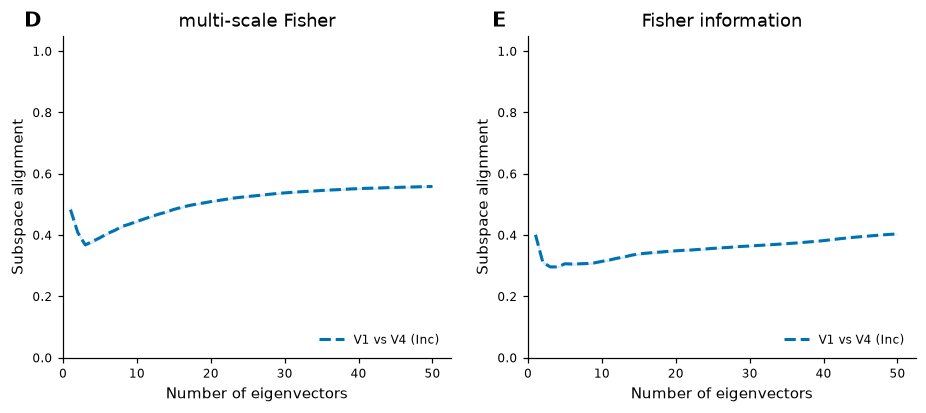

CPU times: user 270 ms, sys: 14.1 ms, total: 285 ms
Wall time: 285 ms


In [8]:
%%time
if metrics_path is None:
    print(
        "Nothing to plot: the alignment needs at least two configurations (see the "
        "message above)."
    )
else:
    show_figure(plot_alignment(metrics_path))